In [1]:
# Load necessary Python Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("ucmr5_pfoa_pfos.csv")

In [3]:
df.head()

,PWSID,PWSName,Size,FacilityID,FacilityName,FacilityWaterType,SamplePointID,SamplePointName,SamplePointType,CollectionDate,...,Contaminant,MRL,Units,MethodID,AnalyticalResultsSign,AnalyticalResultValue,SampleEventCode,MonitoringRequirement,Region,State
0,010106001,Mashantucket Pequot Water System,L,00006,MPTN WTP,GU,TP1,Entry point to Dist. System,EP,9/27/2023,...,PFOS,0.004,µg/L,EPA 533,<,NaN,SE1,AM,1,01
1,010106001,Mashantucket Pequot Water System,L,00006,MPTN WTP,GU,TP1,Entry point to Dist. System,EP,9/27/2023,...,PFOA,0.004,µg/L,EPA 533,=,0.0074,SE1,AM,1,01
2,010106001,Mashantucket Pequot Water System,L,00006,MPTN WTP,GU,TP1,Entry point to Dist. System,EP,10/10/2023,...,PFOA,0.004,µg/L,EPA 533,<,NaN,SE2,AM,1,01
3,010106001,Mashantucket Pequot Water System,L,00006,MPTN WTP,GU,TP1,Entry point to Dist. System,EP,10/10/2023,...,PFOS,0.004,µg/L,EPA 533,<,NaN,SE2,AM,1,01
4,010106001,Mashantucket Pequot Water System,L,00006,MPTN WTP,GU,TP1,Entry point to Dist. System,EP,2/7/2024,...,PFOA,0.004,µg/L,EPA 533,=,0.0071,SE3,AM,1,01


In [4]:
df.sample(10)

,PWSID,PWSName,Size,FacilityID,FacilityName,FacilityWaterType,SamplePointID,SamplePointName,SamplePointType,CollectionDate,...,Contaminant,MRL,Units,MethodID,AnalyticalResultsSign,AnalyticalResultValue,SampleEventCode,MonitoringRequirement,Region,State
660,105300002,LUMMI TRIBAL WATER DISTRICT,S,CC01,LUMMI TRIBAL WATER DISTRICT,SW,S70,BELLINGHAM INTERTIE TAP,EP,2/11/2025,...,PFOS,0.004,µg/L,EPA 533,<,NaN,SE1,AM,10,10
91088,PA1150166,PA AMERICAN ROYERSFORD,L,00105,Merlin Hills TP,GW,105,Merlin Hills Finished Water,EP,1/8/2024,...,PFOS,0.004,µg/L,EPA 533,<,NaN,SE1,AM,3,PA
4846,AL0001508,QUINT-MAR WATER AUTHORITY,S,TP101,QUINT-MAR WATER AUTHORITY,GW,RT01,WELL # 1 + TREATMENT PLANT FINISHED,EP,2/6/2024,...,PFOA,0.004,µg/L,EPA 533,<,NaN,SE1,AM,4,AL
770,AK2210906,MOA MUNICIPALITY OF ANCHORAGE,L,46243,Well # 12 TP,GW,37152,Well #12 DS EP,EP,1/31/2023,...,PFOA,0.004,µg/L,EPA 533,<,NaN,SE1,AM,10,AK
17711,CA3310021,JURUPA COMMUNITY SD,L,91809,Chino II Desalter,GW,3310021809,Entry Point to Dist. System,EP,6/8/2023,...,PFOS,0.004,µg/L,EPA 533,<,NaN,SE1,AM,9,CA
19165,CA3410031,CALAM - ANTELOPE,L,91038,Watt Ave. Well,GW,3410031038,EP #26 - Watt Ave. Well Treated,EP,6/24/2025,...,PFOS,0.004,µg/L,EPA 533,<,NaN,SE1,AM,9,CA
24348,CA5410010,"PORTERVILLE, CITY OF",L,91820,Well C-18,GW,5410010820,EP #65 - Well C-18 Treated,EP,11/20/2023,...,PFOA,0.004,µg/L,EPA 533,<,NaN,SE2,AM,9,CA
68832,NC0197015,MULBERRY-FAIRPLAINS WTR ASSOC,S,FL1A,MULBERRY-FAIRPLAINS WTR ASSOC,SW,MM1,MASTER METER #1,EP,1/11/2023,...,PFOA,0.004,µg/L,EPA 533,<,NaN,SE1,AM,4,NC
23903,CA5010010,"MODESTO, CITY OF",L,91936,Well 259,GW,5010010936,EP for Well 259,EP,5/16/2024,...,PFOS,0.004,µg/L,EPA 533,=,0.0091,SE2,AM,9,CA
38490,ID1280147,POST FALLS CITY OF,L,00981,Well 7 TP,GW,EP7WFTP,Well 7 Finished,EP,3/16/2023,...,PFOS,0.004,µg/L,EPA 533,<,NaN,SE1,AM,10,ID


In [5]:
df.shape

(128400, 21)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128400 entries, 0 to 128399
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   PWSID                  128400 non-null  object 
 1   PWSName                128400 non-null  object 
 2   Size                   128400 non-null  object 
 3   FacilityID             128396 non-null  object 
 4   FacilityName           128396 non-null  object 
 5   FacilityWaterType      128400 non-null  object 
 6   SamplePointID          128400 non-null  object 
 7   SamplePointName        128400 non-null  object 
 8   SamplePointType        128400 non-null  object 
 9   CollectionDate         128400 non-null  object 
 10  SampleID               128400 non-null  object 
 11  Contaminant            128400 non-null  object 
 12  MRL                    128400 non-null  float64
 13  Units                  128400 non-null  object 
 14  MethodID               128400 non-nu

In [7]:
df["FacilityID"].describe()

count     128396
unique      9326
top        00001
freq        5250
Name: FacilityID, dtype: object

In [8]:
df["PWSID"].describe()

count        128400
unique        10289
top       NY5110526
freq            960
Name: PWSID, dtype: object

In [9]:
df.isna().sum()

PWSID                         0
PWSName                       0
Size                          0
FacilityID                    4
FacilityName                  4
FacilityWaterType             0
SamplePointID                 0
SamplePointName               0
SamplePointType               0
CollectionDate                0
SampleID                      0
Contaminant                   0
MRL                           0
Units                         0
MethodID                      0
AnalyticalResultsSign         0
AnalyticalResultValue    119752
SampleEventCode               0
MonitoringRequirement         0
Region                        0
State                         0
dtype: int64

AnalyticalResultsSign Sign indicating whether the analytical result is less than (<) the UCMR 5 MRL or equal to (=) a numeric value at or above the UCMR 5 MRL
AnalyticalResultValue Numeric value of the analytical result in µg/L for the contaminants. Null (or blank) values represent results less than the UCMR 5 MRL

In [10]:
print(df['AnalyticalResultsSign'].value_counts())
print()
print(f"Total Samples: {len(df)}")
print(f"Non-detects: (Analytical Result Value has no value) -> {df['AnalyticalResultValue'].isna().sum()}")
print(f"Detections:(Analytical Result Value has value) -> {df['AnalyticalResultValue'].notna().sum()}")
print(f"Detection rate: {(df['AnalyticalResultValue'].notna().sum() / len(df)) * 100:.2f}%")

AnalyticalResultsSign
<    119752
=      8648
Name: count, dtype: int64

Total Samples: 128400
Non-detects: (Analytical Result Value has no value) -> 119752
Detections:(Analytical Result Value has value) -> 8648
Detection rate: 6.74%


In [11]:
int(df["FacilityID"].isna().sum())

4

PWSID NV0000167 was removed cause the Facility ID was missing

In [12]:
int(df["FacilityName"].isna().sum())

4

In [13]:
df[df["FacilityID"].isna()]

,PWSID,PWSName,Size,FacilityID,FacilityName,FacilityWaterType,SamplePointID,SamplePointName,SamplePointType,CollectionDate,...,Contaminant,MRL,Units,MethodID,AnalyticalResultsSign,AnalyticalResultValue,SampleEventCode,MonitoringRequirement,Region,State
79185,NV0000167,VIRGIN VALLEY WATER DISTRICT,L,NaN,Treatment Plant #1A (TP1A),GW,16,Entry Point to Dist. System,EP,10/3/2023,...,PFOA,0.004,µg/L,EPA 533,<,NaN,SE1,AM,9,NV
79186,NV0000167,VIRGIN VALLEY WATER DISTRICT,L,NaN,Treatment Plant #1A (TP1A),GW,16,Entry Point to Dist. System,EP,10/3/2023,...,PFOS,0.004,µg/L,EPA 533,<,NaN,SE1,AM,9,NV
79187,NV0000167,VIRGIN VALLEY WATER DISTRICT,L,NaN,Treatment Plant #1A (TP1A),GW,16,Entry Point to Dist. System,EP,3/26/2024,...,PFOS,0.004,µg/L,EPA 533,<,NaN,SE2,AM,9,NV
79188,NV0000167,VIRGIN VALLEY WATER DISTRICT,L,NaN,Treatment Plant #1A (TP1A),GW,16,Entry Point to Dist. System,EP,3/26/2024,...,PFOA,0.004,µg/L,EPA 533,<,NaN,SE2,AM,9,NV


In [14]:
df.loc[df["FacilityID"].isna(), "PWSID"]

79185    NV0000167
79186    NV0000167
79187    NV0000167
79188    NV0000167
Name: PWSID, dtype: object

In [15]:
df[df["FacilityName"].isna()]

,PWSID,PWSName,Size,FacilityID,FacilityName,FacilityWaterType,SamplePointID,SamplePointName,SamplePointType,CollectionDate,...,Contaminant,MRL,Units,MethodID,AnalyticalResultsSign,AnalyticalResultValue,SampleEventCode,MonitoringRequirement,Region,State
43440,IL1970500,LOCKPORT,L,IL1970500,NaN,GW,TP16,WELL 15 FINISHED WATER,EP,12/19/2023,...,PFOA,0.004,µg/L,EPA 533,<,NaN,SE1,AM,5,IL
43441,IL1970500,LOCKPORT,L,IL1970500,NaN,GW,TP16,WELL 15 FINISHED WATER,EP,12/19/2023,...,PFOS,0.004,µg/L,EPA 533,<,NaN,SE1,AM,5,IL
43442,IL1970500,LOCKPORT,L,IL1970500,NaN,GW,TP16,WELL 15 FINISHED WATER,EP,8/28/2024,...,PFOA,0.004,µg/L,EPA 533,<,NaN,SE2,AM,5,IL
43443,IL1970500,LOCKPORT,L,IL1970500,NaN,GW,TP16,WELL 15 FINISHED WATER,EP,8/28/2024,...,PFOS,0.004,µg/L,EPA 533,<,NaN,SE2,AM,5,IL


PWSID IL1970500	 had Facility Name missing but Facility ID was present, so didn't remove this.

In [16]:
df = df.dropna(subset=["FacilityID"]).reset_index(drop=True)

In [17]:
len(df)

128396

In [18]:
df['PWSID'].nunique()

10289

In [19]:
# Create Concentration column: detected values stay as-is; non-detects (NaN) replaced with 0
df['Concentration'] = df['AnalyticalResultValue'].fillna(0)

In [20]:
# Compute the average PFAS concentration at each entry point (PWSID + FacilityID)
# separately for each contaminant (PFOA and PFOS)
ep_avg = (
    df.groupby(["PWSID", "FacilityID", "Contaminant"])["Concentration"]
    .mean()
    .reset_index()
)
ep_avg

,PWSID,FacilityID,Contaminant,Concentration
0,010106001,00006,PFOA,0.005275
1,010106001,00006,PFOS,0.000000
2,010109005,90001,PFOA,0.000000
3,010109005,90001,PFOS,0.000000
4,020000005,EP001,PFOA,0.000000
...,...,...,...,...
52869,WY5680085,TP01,PFOS,0.000000
52870,WY5680095,TP02,PFOA,0.000000
52871,WY5680095,TP02,PFOS,0.000000
52872,WY5680122,20001,PFOA,0.000000


In [21]:
# Reshape the entry-point–level data so that each row represents one entry point
# (PWSID + FacilityID), with separate columns for average PFOA and PFOS concentrations
ep_table = (
    ep_avg
    .pivot(
        index = ['PWSID','FacilityID'],
        columns = 'Contaminant', values = 'Concentration'
    )
    .reset_index()
)
ep_table.columns.name = None

In [22]:
ep_table

,PWSID,FacilityID,PFOA,PFOS
0,010106001,00006,0.005275,0.0
1,010109005,90001,0.000000,0.0
2,020000005,EP001,0.000000,0.0
3,020000008,GW001,0.000000,0.0
4,020000008,SW001,0.000000,0.0
...,...,...,...,...
26432,WY5601569,TP02,0.000000,0.0
26433,WY5680074,TP01,0.000000,0.0
26434,WY5680085,TP01,0.000000,0.0
26435,WY5680095,TP02,0.000000,0.0


In [23]:
# Set threshold at 80% of 0.004 µg/L (i.e., 0.0032)
threshold = 0.004 * 0.8  # 0.0032

# Flag where max PFOA or PFOS concentration exceeds threshold
ep_table["exceeds"] = (
    (ep_table["PFOA"] > threshold) |
    (ep_table["PFOS"] > threshold)
)


In [24]:
# no. of PWSID
ep_table['PWSID'].nunique()

10289

In [25]:
ep_table.head(20)

,PWSID,FacilityID,PFOA,PFOS,exceeds
0,010106001,00006,0.005275,0.0,True
1,010109005,90001,0.000000,0.0,False
2,020000005,EP001,0.000000,0.0,False
3,020000008,GW001,0.000000,0.0,False
4,020000008,SW001,0.000000,0.0,False
5,040000002,TP201,0.000000,0.0,False
6,040000002,TP202,0.000000,0.0,False
7,043740039,37407,0.000000,0.0,False
8,050593203,02018,0.000000,0.0,False
9,055293201,00051,0.000000,0.0,False


In [26]:
ep_table.loc[(ep_table['PWSID'] == 'IL0316000') | (ep_table['PWSID'] == "NY7003493")]

,PWSID,FacilityID,PFOA,PFOS,exceeds
8723,IL0316000,00001,0.0,0.0,False
8724,IL0316000,00002,0.0,0.0,False
18010,NY7003493,94001,0.0,0.0,False
18011,NY7003493,94002,0.0,0.0,False
18012,NY7003493,94003,0.0,0.0,False
18013,NY7003493,94004,0.0,0.0,False


In [27]:
total_exceeding_facilities = ep_table["exceeds"].sum()

print(f"Total entry points: {len(ep_table)}")
print(f"Entry points exceeding threshold: {total_exceeding_facilities}")
print(f"Percentage: {total_exceeding_facilities / len(ep_table) * 100:.1f}%")

Total entry points: 26437
Entry points exceeding threshold: 2229
Percentage: 8.4%


### Merge UCMR5 with SDWA for Population Serve Count

In [28]:
sdwa = pd.read_excel("SDWA_PUB_WATER_SYSTEMS.xlsx")

In [29]:
sdwa.head()

,SUBMISSIONYEARQUARTER,PWSID,PWS_NAME,PRIMACY_AGENCY_CODE,EPA_REGION,SEASON_BEGIN_DATE,SEASON_END_DATE,PWS_ACTIVITY_CODE,PWS_DEACTIVATION_DATE,PWS_TYPE_CODE,...,LAST_REPORTED_DATE,STATE_CODE,SOURCE_WATER_PROTECTION_CODE,SOURCE_PROTECTION_BEGIN_DATE,OUTSTANDING_PERFORMER,OUTSTANDING_PERFORM_BEGIN_DATE,REDUCED_RTCR_MONITORING,REDUCED_MONITORING_BEGIN_DATE,REDUCED_MONITORING_END_DATE,SEASONAL_STARTUP_SYSTEM
0,2025Q2,WA5325264,HANNAH HEIGHTS #2 WATER USERS ASSN,WA,10,NaT,NaT,A,NaT,CWS,...,2025-06-27,WA,NaN,NaT,Y,2024-06-12,NaN,NaT,NaT,NaN
1,2025Q2,LA1119034,GIL-GAL WATER SYSTEM,LA,6,NaT,NaT,A,NaT,CWS,...,2025-06-18,LA,N,NaT,NaN,NaT,NaN,NaT,NaT,NaN
2,2025Q2,NC0120414,THE MOUNTAIN FOLK CENTER,NC,4,2026-01-01,2026-12-31,A,NaT,TNCWS,...,2025-06-26,NC,NaN,NaT,NaN,NaT,NaN,NaT,NaT,NaN
3,2025Q2,AZ0413182,THAI GARDENS,AZ,9,2026-01-01,2026-12-31,A,NaT,TNCWS,...,2025-06-30,AZ,N,NaT,NaN,NaT,NaN,NaT,NaT,NaN
4,2025Q2,LA1073003,BETTER WATERWORKS WATER SYSTEM,LA,6,NaT,NaT,A,NaT,CWS,...,2025-06-18,LA,N,NaT,NaN,NaT,NaN,NaT,NaT,NaN


In [30]:
sdwa.isna().sum()

SUBMISSIONYEARQUARTER                  0
PWSID                                  0
PWS_NAME                             897
PRIMACY_AGENCY_CODE                    0
EPA_REGION                             0
SEASON_BEGIN_DATE                  63559
SEASON_END_DATE                    63559
PWS_ACTIVITY_CODE                      0
PWS_DEACTIVATION_DATE             143268
PWS_TYPE_CODE                          0
DBPR_SCHEDULE_CAT_CODE            395191
CDS_ID                            416626
GW_SW_CODE                          3267
LT2_SCHEDULE_CAT_CODE             430184
OWNER_TYPE_CODE                    49287
POPULATION_SERVED_COUNT                0
POP_CAT_2_CODE                         0
POP_CAT_3_CODE                         0
POP_CAT_4_CODE                         0
POP_CAT_5_CODE                         0
POP_CAT_11_CODE                        0
PRIMACY_TYPE                           0
PRIMARY_SOURCE_CODE                 3267
IS_GRANT_ELIGIBLE_IND                  0
IS_WHOLESALER_IN

In [31]:
# Created a new table ep_table_with_pop by merging ep_table with population served data from sdwa using PWSID
ep_table_with_pop = ep_table.merge(sdwa[['PWSID', 'POPULATION_SERVED_COUNT']], on = 'PWSID', how = 'left')

In [32]:
# total length of the ep_table_with_pop
len(ep_table_with_pop)

26437

In [33]:
ep_table_with_pop.isna().sum()

PWSID                        0
FacilityID                   0
PFOA                         0
PFOS                         0
exceeds                      0
POPULATION_SERVED_COUNT    163
dtype: int64

In [34]:
# Identify systems that are missing population data to check coverage of the SDWA merge 
missing_population = ep_table_with_pop.loc[ep_table_with_pop['POPULATION_SERVED_COUNT'].isna()]
missing_population.head()

,PWSID,FacilityID,PFOA,PFOS,exceeds,POPULATION_SERVED_COUNT
0,010106001,00006,0.005275,0.0,True,NaN
1,010109005,90001,0.000000,0.0,False,NaN
2,020000005,EP001,0.000000,0.0,False,NaN
3,020000008,GW001,0.000000,0.0,False,NaN
4,020000008,SW001,0.000000,0.0,False,NaN


In [35]:
missing_population['PWSID'].nunique()

102

In [36]:
missing_population.loc[missing_population['exceeds']]

,PWSID,FacilityID,PFOA,PFOS,exceeds,POPULATION_SERVED_COUNT
0,010106001,00006,0.005275,0.00000,True,NaN
116,090600147,EP004,0.002800,0.00445,True,NaN
139,090605153,90005,0.005650,0.00000,True,NaN


ZIPCODE of the PWSID that exceeds the 80% threshold of PFOA or PFOS but has the POPULATION SERVE COUNT MISSING:

    PWSID         ZIP
    010106001 -> 06338
    090600147 -> 92082
    090605013 -> 92593

In [37]:
ep_table_with_pop.loc[
    ep_table_with_pop["PWSID"].isin(
        missing_population.loc[missing_population["exceeds"], "PWSID"].unique()
    ),
    ["PWSID", "FacilityID", "exceeds"]
].sort_values(["PWSID", "FacilityID"])


,PWSID,FacilityID,exceeds
0,010106001,00006,True
114,090600147,EP002,False
115,090600147,EP003,False
116,090600147,EP004,True
136,090605153,90001,False
137,090605153,90002,False
138,090605153,90004,False
139,090605153,90005,True


Missing Population Data and PWSID Mapping

When the UCMR5 entry-point PFAS data were merged with SDWA Public Water System data to add population served (POPULATION_SERVED_COUNT), some entry points could not be assigned population values. This occurred because the corresponding PWSIDs were not present in the SDWA dataset.

A Public Water System Identification Code (PWSID) uniquely identifies each water system. Most PWSIDs begin with a two-letter state abbreviation followed by numbers. However, some systems in UCMR5 use different formats, including tribal and regional identifiers. For example, systems with PWSIDs beginning with NN (Navajo Nation) appear in UCMR5 but are not included in SDWA population records. Utah systems also use a special format that begins with UTAH.

Because the SDWA population dataset relies on state-based PWSID formats, these regional and tribal PWSIDs could not be matched, resulting in missing population values for all entry points within those systems.

In this analysis, population was allocated at the entry-point level by evenly dividing system population across entry points. For systems without population data in SDWA, population could not be assigned to their entry points. These entry points were excluded from population-weighted analyses but retained for exceedance counts and other entry-point summaries.

Overall, fewer than 1% of systems lacked population served information. Given the small number of affected systems, excluding them from population-based analyses does not meaningfully affect the results. If needed, population information for these systems could be estimated in future work using ZIP-code–based datasets.

In [38]:
# removed rows with missing population serve count
ep_table_with_pop = ep_table_with_pop.dropna(subset = ['POPULATION_SERVED_COUNT']).reset_index(drop=True)

In [39]:
ep_table_with_pop

,PWSID,FacilityID,PFOA,PFOS,exceeds,POPULATION_SERVED_COUNT
0,AK2110342,29349,0.0,0.0,False,38526.0
1,AK2110342,29360,0.0,0.0,False,38526.0
2,AK2110601,10001,0.0,0.0,False,10947.0
3,AK2110601,10004,0.0,0.0,False,10947.0
4,AK2120232,TP001,0.0,0.0,False,8937.0
...,...,...,...,...,...,...
26269,WY5601569,TP02,0.0,0.0,False,580.0
26270,WY5680074,TP01,0.0,0.0,False,4300.0
26271,WY5680085,TP01,0.0,0.0,False,7675.0
26272,WY5680095,TP02,0.0,0.0,False,4514.0


In [40]:
ep_table_with_pop.shape

(26274, 6)

### Entry-Point Population Allocation and Population Binning

To analyze PFAS at the entry-point level, the population served by each water system was split across its entry points. First, we counted how many entry points each system has by counting unique FacilityID values for each PWSID. The total system population was then divided evenly across those entry points.

The assigned population for each entry point (Ep_Population) was added back to the entry-point PFAS dataset so that each row represents one entry point with an estimated population served. Finally, entry points were grouped into population size categories using the assign_pop_bin() function, ensuring that population binning is based on entry points rather than entire water systems for all further analysis.

In [41]:
ep_counts = (
    ep_table_with_pop
    .groupby("PWSID")["FacilityID"]
    .nunique()
    .reset_index(name="n_entry_points")
)

ep_counts.sample(10)


,PWSID,n_entry_points
502,AR0000787,1
3932,MA2151001,2
691,CA0710001,1
6737,OH7400411,1
1299,CA5010017,6
6228,NY2602381,1
1447,CO0135233,1
7351,PA5100042,1
6995,OR4100225,2
8044,TN0000615,3


In [42]:
ep_with_population = (
    ep_table_with_pop[["PWSID", "FacilityID", "POPULATION_SERVED_COUNT"]]
    .drop_duplicates()
    .merge(ep_counts, on="PWSID", how="left")
)
ep_with_population

,PWSID,FacilityID,POPULATION_SERVED_COUNT,n_entry_points
0,AK2110342,29349,38526.0,2
1,AK2110342,29360,38526.0,2
2,AK2110601,10001,10947.0,2
3,AK2110601,10004,10947.0,2
4,AK2120232,TP001,8937.0,1
...,...,...,...,...
26269,WY5601569,TP02,580.0,1
26270,WY5680074,TP01,4300.0,1
26271,WY5680085,TP01,7675.0,1
26272,WY5680095,TP02,4514.0,1


In [43]:
ep_with_population['Ep_Population'] = (
    ep_with_population['POPULATION_SERVED_COUNT']/ep_with_population['n_entry_points']
)
ep_with_population

,PWSID,FacilityID,POPULATION_SERVED_COUNT,n_entry_points,Ep_Population
0,AK2110342,29349,38526.0,2,19263.0
1,AK2110342,29360,38526.0,2,19263.0
2,AK2110601,10001,10947.0,2,5473.5
3,AK2110601,10004,10947.0,2,5473.5
4,AK2120232,TP001,8937.0,1,8937.0
...,...,...,...,...,...
26269,WY5601569,TP02,580.0,1,580.0
26270,WY5680074,TP01,4300.0,1,4300.0
26271,WY5680085,TP01,7675.0,1,7675.0
26272,WY5680095,TP02,4514.0,1,4514.0


In [44]:
ep_table_final = ep_table_with_pop.merge(
    ep_with_population[["PWSID", "FacilityID", "Ep_Population"]],
    on=["PWSID", "FacilityID"],
    how="left"
)

ep_table_final.head()


,PWSID,FacilityID,PFOA,PFOS,exceeds,POPULATION_SERVED_COUNT,Ep_Population
0,AK2110342,29349,0.0,0.0,False,38526.0,19263.0
1,AK2110342,29360,0.0,0.0,False,38526.0,19263.0
2,AK2110601,10001,0.0,0.0,False,10947.0,5473.5
3,AK2110601,10004,0.0,0.0,False,10947.0,5473.5
4,AK2120232,TP001,0.0,0.0,False,8937.0,8937.0


In [45]:
def assign_pop_bin(pop):
    if pop <= 100:
        return '25 - 100'
    elif pop <= 500:
        return '101 - 500'
    elif pop <= 1000:
        return '501 - 1,000'
    elif pop <= 3300:
        return '1,001 - 3,300'
    elif pop <= 10000:
        return '3,301 - 10,000'
    elif pop <= 50000:
        return '10,001 - 50,000'
    elif pop <= 100000:
        return '50,001 - 100,000'
    elif pop <= 1000000:
        return '100,001 - 1,000,000'
    else:
        return '> 1,000,000'

In [46]:
ep_table_final['Population_bin'] = ep_table_final['Ep_Population'].apply(assign_pop_bin)

In [47]:
ep_table_final

,PWSID,FacilityID,PFOA,PFOS,exceeds,POPULATION_SERVED_COUNT,Ep_Population,Population_bin
0,AK2110342,29349,0.0,0.0,False,38526.0,19263.0,"10,001 - 50,000"
1,AK2110342,29360,0.0,0.0,False,38526.0,19263.0,"10,001 - 50,000"
2,AK2110601,10001,0.0,0.0,False,10947.0,5473.5,"3,301 - 10,000"
3,AK2110601,10004,0.0,0.0,False,10947.0,5473.5,"3,301 - 10,000"
4,AK2120232,TP001,0.0,0.0,False,8937.0,8937.0,"3,301 - 10,000"
...,...,...,...,...,...,...,...,...
26269,WY5601569,TP02,0.0,0.0,False,580.0,580.0,"501 - 1,000"
26270,WY5680074,TP01,0.0,0.0,False,4300.0,4300.0,"3,301 - 10,000"
26271,WY5680085,TP01,0.0,0.0,False,7675.0,7675.0,"3,301 - 10,000"
26272,WY5680095,TP02,0.0,0.0,False,4514.0,4514.0,"3,301 - 10,000"


In [48]:
ep_table_final.shape

(26274, 8)

In [49]:
ep_table_final.to_csv('ep_table.csv', index=False)

This bar chart shows how many entry points fall into each population size group. Each entry point is grouped based on the number of people it serves, and the chart counts how many entry points belong to each group.

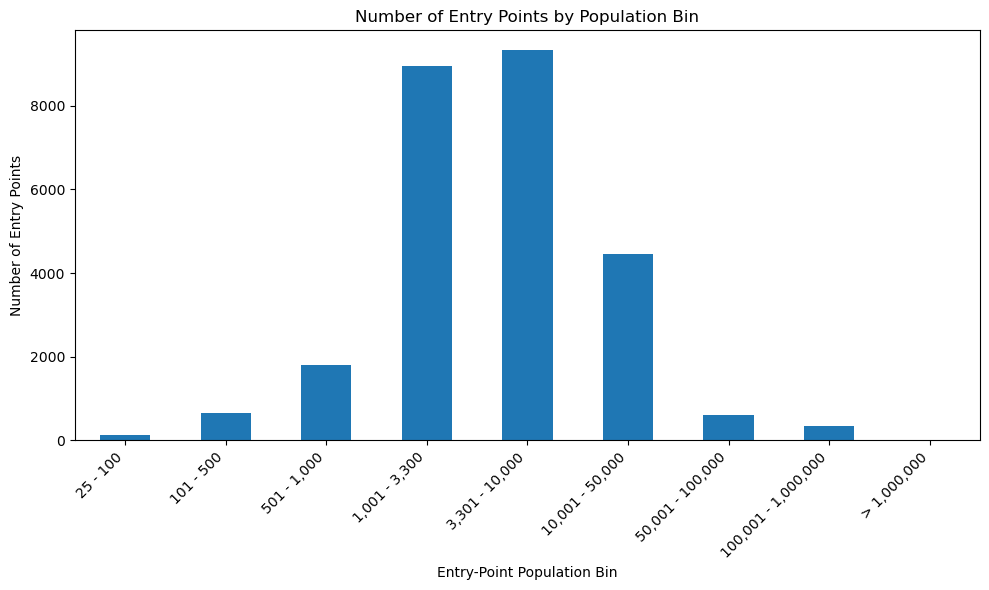

In [50]:
bin_order = [
    '25 - 100',
    '101 - 500',
    '501 - 1,000',
    '1,001 - 3,300',
    '3,301 - 10,000',
    '10,001 - 50,000',
    '50,001 - 100,000',
    '100,001 - 1,000,000',
    '> 1,000,000'
]

ep_bin_counts = (
    ep_table_final["Population_bin"]
    .value_counts()
    .reindex(bin_order, fill_value=0)
)

plt.figure(figsize=(10, 6))
ep_bin_counts.plot(kind="bar")

plt.xlabel("Entry-Point Population Bin")
plt.ylabel("Number of Entry Points")
plt.title("Number of Entry Points by Population Bin")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


This box-and-whisker plot shows how the number of entry points in a water system varies across different system population sizes. Each box summarizes how many entry points systems typically have within each population group, helping show that larger systems generally have more entry points than smaller systems.

In [51]:
pws_table = (
    ep_table_with_pop.groupby("PWSID")
    .agg(
        Population=("POPULATION_SERVED_COUNT", "first"),
        n_entry_points=("FacilityID", "nunique")
    )
    .reset_index()
)
pws_table

,PWSID,Population,n_entry_points
0,AK2110342,38526.0,2
1,AK2110601,10947.0,2
2,AK2120232,8937.0,1
3,AK2130075,9448.0,1
4,AK2210605,794.0,1
...,...,...,...
10182,WY5601569,580.0,1
10183,WY5680074,4300.0,1
10184,WY5680085,7675.0,1
10185,WY5680095,4514.0,1


In [52]:
pws_table["Population_bin"] = pws_table["Population"].apply(assign_pop_bin)
data = [
    pws_table.loc[pws_table["Population_bin"] == b, "n_entry_points"]
    for b in bin_order
]


### Bin-specific EPs per PWS (M vector)
Average number of entry points per water system in each **system** population bin (bins from the PWS's total `POPULATION_SERVED_COUNT`). This replaces the single national multiplier (M = 2.58) in `03_scaling`, because larger systems have many more EPs than small ones. Saved to `eps_per_pws_by_bin.csv` for use in `03_scaling`.

In [53]:
# Average number of EPs per PWS in each system population bin
eps_per_pws_by_bin = (
    pws_table.groupby("Population_bin")
    .agg(n_systems=("PWSID", "count"),
         total_EPs=("n_entry_points", "sum"),
         avg_EPs_per_PWS=("n_entry_points", "mean"))
    .reindex(bin_order)
)
eps_per_pws_by_bin["avg_EPs_per_PWS"] = eps_per_pws_by_bin["avg_EPs_per_PWS"].round(4)

# Check: every bin has at least one UCMR5 system, and totals match ep_table
assert eps_per_pws_by_bin["n_systems"].notna().all(), "A population bin has no UCMR5 systems"
assert eps_per_pws_by_bin["total_EPs"].sum() == len(ep_table_with_pop)

eps_per_pws_by_bin.to_csv("eps_per_pws_by_bin.csv")
eps_per_pws_by_bin

,n_systems,total_EPs,avg_EPs_per_PWS
Population_bin,,,
25 - 100,95,113,1.1895
101 - 500,115,138,1.2000
"501 - 1,000",247,341,1.3806
"1,001 - 3,300",489,789,1.6135
"3,301 - 10,000",4705,9556,2.0310
"10,001 - 50,000",3472,9628,2.7730
"50,001 - 100,000",582,2272,3.9038
"100,001 - 1,000,000",456,2981,6.5373
"> 1,000,000",26,456,17.5385


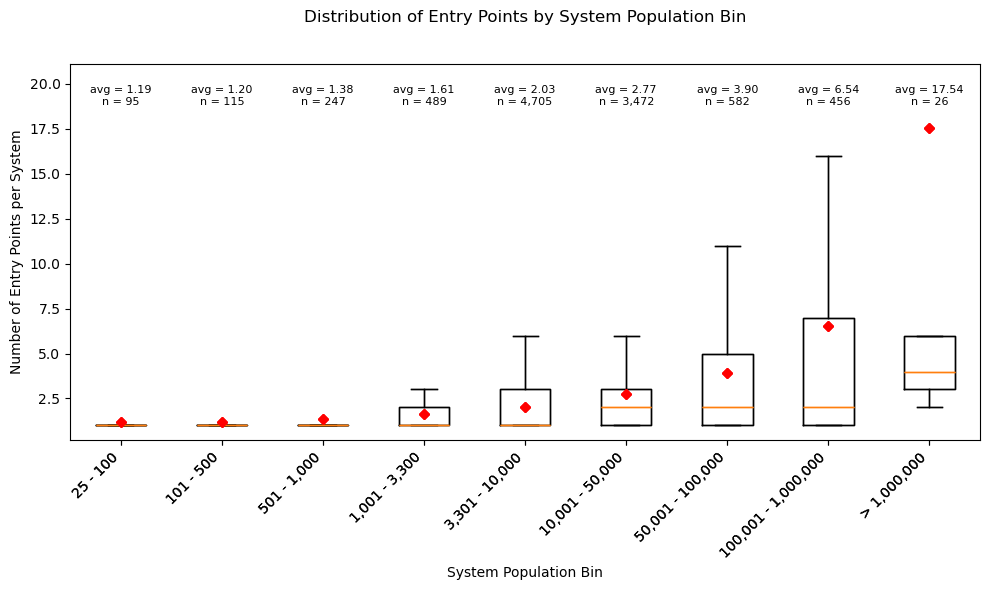

In [54]:
plt.figure(figsize=(10, 6))
plt.boxplot(data, tick_labels=bin_order, showfliers=False, showmeans=True,
            meanprops=dict(marker="D", markerfacecolor="red", markeredgecolor="red", markersize=5))

# Label each box with the average EPs per PWS and the number of systems
y_top = plt.ylim()[1]
for pos, b in enumerate(bin_order, start=1):
    avg = eps_per_pws_by_bin.loc[b, "avg_EPs_per_PWS"]
    n = int(eps_per_pws_by_bin.loc[b, "n_systems"])
    plt.text(pos, y_top * 1.02, f"avg = {avg:.2f}\nn = {n:,}",
             ha="center", va="bottom", fontsize=8)
plt.ylim(top=y_top * 1.15)

plt.xlabel("System Population Bin")
plt.ylabel("Number of Entry Points per System")
plt.title("Distribution of Entry Points by System Population Bin", pad=30)
plt.xticks(rotation=45, ha="right")
plt.boxplot(data, tick_labels=bin_order, showfliers=False, showmeans=True,
            meanprops=dict(marker="D", markerfacecolor="red", markeredgecolor="red", markersize=5))
plt.tight_layout()
plt.show()

Note on the labels: n is the number of UCMR5 water systems in each population bin, and avg is the average number of entry points (EPs) per system in that bin. These averages are used in 03_scaling in place of the single national multiplier (M = 2.58). Outliers are not shown in the boxes, but they are included in the average. This is why, for some bins (e.g. > 1,000,000), the average is higher than the top of the box: a few very large systems have many EPs and pull the average up.